In [1]:
import pandas as pd
from IPython.display import display

In [2]:
from collections import Counter
from datasets import load_dataset

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")

# Show the sizes of the existing splits.
print("\nExisting Dataset Splits:\n")
for name, split in dataset.items():
    print(f"{name} - {len(split)} examples")

# Read the labels from the training dataset.
train = dataset["train"]
labels = train.features["label"].names

# Count how many examples are in each class.
print("\nTraining Examples Per Class:\n")
counts = Counter(train["label"])
for i, label in enumerate(labels):
    print(f"{label} - {counts[i]} examples")

# Print 5 training examples.
print("\nFive Training Examples:")
for example in train.shuffle(seed=13).select(range(5)):
    print(f"\nText: {example['text']}")
    print(f"Label: {labels[example['label']]}")


Existing Dataset Splits:

train - 3257 examples
test - 1421 examples
validation - 374 examples

Training Examples Per Class:

anger - 1400 examples
joy - 708 examples
optimism - 294 examples
sadness - 855 examples

Five Training Examples:

Text: Sometimes The Worst Place You Can Be Is In Your Own Head.'\n\n #quotes #worstenemy  #thinktoomuch
Label: sadness

Text: @user @user Yep, as I pointed out before, it's the politics of loathing. That's why the big candidates are so horrible.
Label: anger

Text: @user I'm confident they will NEVER experience our successes of last 50yrs. Best they can hope for is to be another Bournemouth #sad
Label: sadness

Text: @user can be as indignant as he wants but the world knows Obama will do nothing and Putin will just do what he wants #Aleppo #Syria
Label: anger

Text: People need a way to escape,escape what?This corrupted world.This reality. This joke.This fury of constant pain &amp; stress.We need a vacation
Label: anger


In [3]:
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from embeddings import Vocabulary, PretrainedEmbeddings
from pathlib import Path
from zipfile import ZipFile

GLOVE_PATH = Path("glove.twitter.27B.zip")
EMBEDDING_DIM = 25


# Extract only the D-dimensional GloVe file from the archive
with ZipFile(GLOVE_PATH) as archive:
    member = f"glove.twitter.27B.{EMBEDDING_DIM}d.txt"
    extracted_path = GLOVE_PATH.with_name(member)

    with archive.open(member) as source, extracted_path.open("wb") as destination:
        destination.write(source.read())

trained_embeddings = PretrainedEmbeddings(
    str(extracted_path),
    EMBEDDING_DIM,
    unk_token="<unk>",
    pad_token="<pad>",
    skip_first_line=False
)

Shape of embedding matrix: (1193515, 25)
Size of vocabulary: 1193515
First few entries in the vocabulary:
<pad> (id=0)
<unk> (id=1)
<user> (id=2)
. (id=3)
: (id=4)
rt (id=5)
, (id=6)
<repeat> (id=7)
<hashtag> (id=8)
<number> (id=9)
Embedding for 'anger': [-0.063143  0.28465  -1.0098    1.6863   -0.013202  0.67061   1.2565
 -1.0969    0.44354   0.33431  -0.42579   0.9627   -3.1405    0.87556
  0.52742   1.1375   -0.41078   0.71686   1.1691   -0.98513   0.27745
  0.63856   0.33257  -0.10149  -0.35101 ]
Embedding for 'joy': [-1.0811e+00 -3.2919e-02 -1.5043e-01  1.3471e+00 -4.1869e-01 -1.2324e-01
  1.0553e+00  2.6657e-02 -9.9019e-02 -6.0421e-01 -4.0589e-01  2.9876e-01
 -3.1435e+00  6.6033e-01 -8.4699e-02  1.1403e-01 -1.8131e-03  6.2786e-01
  5.8898e-01 -1.0829e-01 -4.3621e-01 -7.7728e-02 -5.8776e-01  8.5420e-01
  2.2741e-01]
Embedding for 'optimism': [-1.0064   -0.57317  -2.1162    0.97437  -0.28261   0.3625    0.95174
 -1.4436    0.99296  -0.76629  -0.23727   0.83335  -1.7878    1.4323
  

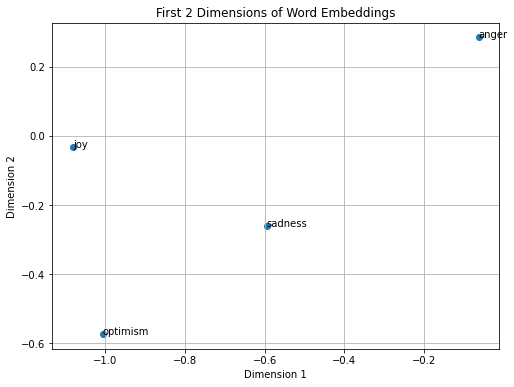

In [4]:
print("Shape of embedding matrix:", trained_embeddings.vectors.shape)
print("Size of vocabulary:", len(trained_embeddings.vocab))
print("First few entries in the vocabulary:")


for word in trained_embeddings.vocab.words[:10]:
    print(f"{word} (id={trained_embeddings.vocab.index(word)})")


for word in ["anger", "joy", "optimism", "sadness"]:
    embedding = trained_embeddings.embed_word(word)
    print(f"Embedding for '{word}': {embedding[:]}")

# plot the first two dimensions of the embeddings for a few words
words_to_plot = ["anger", "joy", "optimism", "sadness"]
embeddings_to_plot = np.array([trained_embeddings.embed_word(word) for word in words_to_plot])  

import matplotlib.pyplot as plt

#Visualise the first two dimensions of the embeddings of the class labels
plt.figure(figsize=(8, 6))
plt.scatter(embeddings_to_plot[:, 0], embeddings_to_plot[:, 1])
for i, word in enumerate(words_to_plot):
    plt.annotate(word, (embeddings_to_plot[i, 0], embeddings_to_plot[i, 1]))
plt.title("First 2 Dimensions of Word Embeddings")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid()
plt.show()

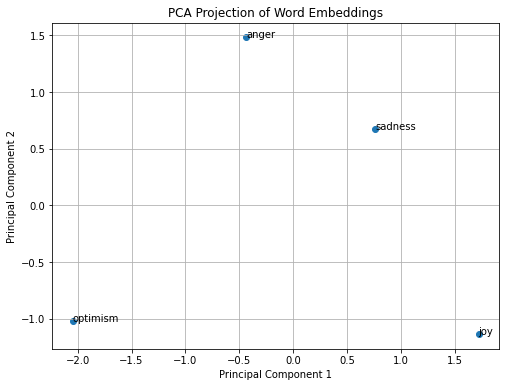

In [5]:
# PCA plot
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(embeddings_to_plot)
embeddings_2d = pca.transform(embeddings_to_plot)

plt.figure(figsize=(8, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1])
for i, word in enumerate(words_to_plot):
    plt.annotate(word, (embeddings_2d[i, 0], embeddings_2d[i, 1]))
plt.title("PCA Projection of Word Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid()
plt.show()

In [6]:
def cos_sim(a, b):
    """Compute the cosine similarity between two vectors a and b."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def topk_ids(embedding_matrix, query_vector, k=10):
    """Return IDs of the k closest valid word vectors."""
    query_norm = np.linalg.norm(query_vector)
    norms = np.linalg.norm(embedding_matrix, axis=1)

    similarities = np.full(len(embedding_matrix), -np.inf)
    valid = norms > 0
    similarities[valid] = (embedding_matrix[valid] @ query_vector) / (norms[valid] * query_norm)

    # In this vocabulary, IDs 0 and 1 are padding and unknown.
    similarities[:2] = -np.inf
    valid_ids = np.flatnonzero(np.isfinite(similarities))

    return valid_ids[np.argsort(similarities[valid_ids])[::-1][:k]]

In [7]:
# Cosine similarity
for i in range(len(words_to_plot)):
    for j in range(i + 1, len(words_to_plot)):
        word_i = words_to_plot[i]
        word_j = words_to_plot[j]
        embedding_i = trained_embeddings.embed_word(word_i)
        embedding_j = trained_embeddings.embed_word(word_j)
        similarity = cos_sim(embedding_i, embedding_j)
        print(f"Cosine similarity between '{word_i}' and '{word_j}': {similarity:.4f}")

Cosine similarity between 'anger' and 'joy': 0.7348
Cosine similarity between 'anger' and 'optimism': 0.7914
Cosine similarity between 'anger' and 'sadness': 0.8817
Cosine similarity between 'joy' and 'optimism': 0.6278
Cosine similarity between 'joy' and 'sadness': 0.8302
Cosine similarity between 'optimism' and 'sadness': 0.7276


In [8]:
# Top k most similar words for each of the class labels
for word in words_to_plot:
    query_vector = trained_embeddings.embed_word(word)
    topk_indices = topk_ids(trained_embeddings.vectors, query_vector, k=10)
    similar_words = [trained_embeddings.vocab.word(i) for i in topk_indices]
    print(f"Top 10 words similar to '{word}': {similar_words}")

Top 10 words similar to 'anger': ['anger', 'fear', 'frustration', 'emotions', 'pain', 'emotion', 'hatred', 'enemy', 'confusion', 'loneliness']
Top 10 words similar to 'joy': ['joy', 'dreams', 'faith', 'grace', 'happiness', 'spirit', 'lord', 'heaven', 'soul', 'god']
Top 10 words similar to 'optimism': ['optimism', 'uncertainty', 'enthusiasm', 'obstacle', 'certainty', 'unhappiness', 'circumstances', 'burden', 'persistence', 'shifting']
Top 10 words similar to 'sadness': ['sadness', 'heartbreak', 'laughter', 'sorrow', 'heartache', 'misery', 'happiness', 'loneliness', 'anger', 'despair']


In [9]:
# inspect analogies, define an embedded vector for an analogy and see which 10 words are most similar in the space
analogy_vector = trained_embeddings.embed_word("pretty") - trained_embeddings.embed_word("man") + trained_embeddings.embed_word("woman")
topk_indices = topk_ids(trained_embeddings.vectors, analogy_vector, k=10)
similar_words = [trained_embeddings.vocab.word(i) for i in topk_indices]
print(f"Top 10 words similar to the analogy 'pretty - man + woman': {similar_words}")

Top 10 words similar to the analogy 'pretty - man + woman': ['beautiful', 'gorgeous', 'sassy', 'precious', 'loving', 'looking', 'attractive', 'fabulous', 'woman', 'stunning']


In [10]:
# class Tokenizer:
#     def tokens(self, text: str) -> list:
#         """Tokenize as a list of string tokens"""
#         raise NotImplementedError("Implement me in subclass")
#     def ids(self, text: str) -> list:
#         """Tokenize as a list of token ids"""
#         raise NotImplementedError("Implement me in subclass")

# class BasicTokenizer(Tokenizer):
#     """
#     Tokenize text (str) using the call method of the object.

#     Here are the  steps:
#     1. lowercase (optional)
#     2. remove punctuation (optional)
#     3. NLT-tokenize
#     4. remove stopwords (optional)

#     Different languages are only supported to the extent that NLTK supports them.
#     If you need something more complex, you need to write your own tokenizer.
#     """

#     def __init__(self, lowercase: bool, remove_punct: bool, remove_stopwords: bool, language='english', vocab: Vocabulary=None):
#         """
#         lowercase: lowercase the text before tokenization
#         remove_punct: remove punctuation
#         remove_stopwords: use NLKT to remove stopwords
#         language: tells NLTK what language-specific rules to use
#         vocab: a Vocabulary object that maintains a correspondence between string symbols and unique ids
#          including a 'default' symbol for unkonwn words.
#          if None, the basic tokenizer will not be able to implement the `ids` method
#         """
#         self.vocab = vocab
#         self.language = language
#         self.lowercase = lowercase
#         self.remove_punct = remove_punct
#         self.remove_stopwords = remove_stopwords
#         if remove_stopwords:
#             self.stopwords = set(nltk.corpus.stopwords.words(language))

#     def tokens(self, text) -> 'list[str]':
#         """Chops text into a list of words/tokens (each a string)"""
#         if self.lowercase:
#             text = text.lower()
#         if self.remove_punct:
#             # sub space for punctuation
#             text = re.sub(r'[^\w\s]', ' ', text)
#         # basic NLT tokenization
#         tokens = nltk.tokenize.word_tokenize(text, language=self.language)
#         if self.remove_stopwords:
#             # filter stopwords
#             tokens = [token for token in tokens if token not in self.stopwords]
#         return tokens

#     def ids(self, text) -> 'list[int]':
#         """
#         Chops text into a list of words/tokens ids.
#         Unknown tokens get the id of the default symbol in the vocabulary.
#         """
#         if self.vocab is None:
#             raise ValueError("I need a vocabulary")
#         return [self.vocab.index(t) for t in self.tokens(text)]


# def read_lines_from_file(path, encoding="utf-8"):
#     if path.endswith('.txt'):
#         with open(path, 'r', encoding=encoding) as f:
#             for line in f:
#                 yield line.strip()
#     elif path.endswith('.gz'):
#         with gzip.open(path, 'rt', encoding=encoding) as f:
#             for line in f:
#                 yield line.strip()
#     elif path.endswith('.zip'):
#         with ZipFile(path) as archive:
#             members = archive.namelist()

#             if len(members) != 1:
#                 raise ValueError(
#                     f"Expected exactly one .txt file in {path}, "
#                     f"found {len(members)}: {members}"
#                 )

#             with archive.open(members[0]) as f:
#                 with TextIOWrapper(f, encoding=encoding) as text:
#                     for line in text:
#                         yield line.strip()
#     else:
#         raise ValueError(f"Unknown format: {path}")


In [11]:
from nltk.tokenize import TweetTokenizer, word_tokenize


tweet_tokenizer = TweetTokenizer(
    preserve_case=False,
    reduce_len=False,
    strip_handles=False,
)

# make the same definition for word_tokenizer as we did for tweet_tokenizer, but using word_tokenize from nltk
word_tokenizer = lambda text: word_tokenize(
    text.lower(),
    language='english',
    preserve_line=True)

tokenizers = {
    "TweetTokenizer": tweet_tokenizer,
    "WordTokenizer": word_tokenizer
}

# sample_text = dataset["train"][0]["text"]

# tweet_tokens = tweet_tokenizer.tokenize(sample_text)
# word_tokens = word_tokenizer(sample_text)

# print("Sample text:", sample_text)
# print("Tweet tokens:", tweet_tokens)
# print("Word tokens:", word_tokens)

# First 5 training examples from the dataset
sample_texts = [example["text"] for example in dataset["train"].select(range(5))]

for text in sample_texts:
    print(f"\nSample text: {text}")
    for name, tokenizer in tokenizers.items():
        if hasattr(tokenizer, "tokenize"):
            tokens = tokenizer.tokenize(text)
        else:
            tokens = tokenizer(text)
        print(f"{name} tokens: {tokens}")


Sample text: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
TweetTokenizer tokens: ['“', 'worry', 'is', 'a', 'down', 'payment', 'on', 'a', 'problem', 'you', 'may', 'never', 'have', "'", '.', 'joyce', 'meyer', '.', '#motivation', '#leadership', '#worry']
WordTokenizer tokens: ['“', 'worry', 'is', 'a', 'down', 'payment', 'on', 'a', 'problem', 'you', 'may', 'never', "have'.", 'joyce', 'meyer.', '#', 'motivation', '#', 'leadership', '#', 'worry']

Sample text: My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs
TweetTokenizer tokens: ['my', 'roommate', ':', "it's", 'okay', 'that', 'we', "can't", 'spell', 'because', 'we', 'have', 'autocorrect', '.', '#terrible', '#firstworldprobs']
WordTokenizer tokens: ['my', 'roommate', ':', 'it', "'s", 'okay', 'that', 'we', 'ca', "n't", 'spell', 'because', 'we', 'have', 'autocorrect.', '#', 'terrible', '#', 'firstworldprobs']

Sample text: No but tha

,Split,Tokenizer,Coverage (%),Known tokens,Total tokens,OOV tokens
0,train,TweetTokenizer,85.736619,51003,59488,8485
1,train,WordTokenizer,93.953329,60272,64151,3879
2,test,TweetTokenizer,84.667159,21762,25703,3941
3,test,WordTokenizer,93.139489,25754,27651,1897
4,validation,TweetTokenizer,83.003128,5572,6713,1141
5,validation,WordTokenizer,92.898194,6789,7308,519


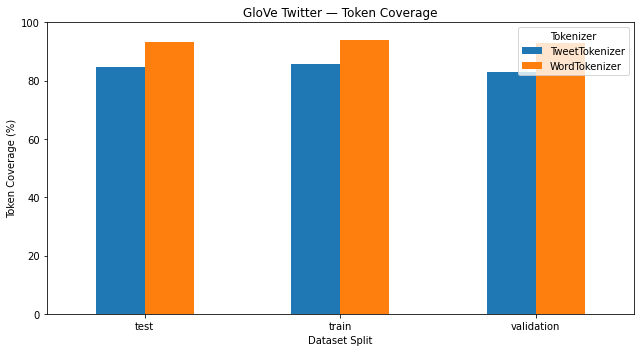

In [12]:
def token_coverage(tokenizer, data, embeddings):
    total_tokens = 0
    known_tokens = 0

    for example in data:
        text = example["text"]

        # Support both tokenizer objects and functions
        if hasattr(tokenizer, "tokenize"):
            tokens = tokenizer.tokenize(text)
        else:
            tokens = tokenizer(text)

        tokens = [token.lower() for token in tokens]

        total_tokens += len(tokens)
        known_tokens += sum(
            token in embeddings for token in tokens
        )

    coverage = (
        100 * known_tokens / total_tokens
        if total_tokens > 0 else 0
    )

    return coverage, known_tokens, total_tokens


# Compare tokenizers across dataset splits
coverage_results = []

for split_name, split in dataset.items():
    for name, tokenizer in tokenizers.items():

        coverage, known, total = token_coverage(
            tokenizer,
            split,
            trained_embeddings
        )

        coverage_results.append({
            "Split": split_name,
            "Tokenizer": name,
            "Coverage (%)": coverage,
            "Known tokens": known,
            "Total tokens": total,
            "OOV tokens": total - known
        })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

import matplotlib.pyplot as plt

coverage_plot = coverage_df.pivot(
    index="Split",
    columns="Tokenizer",
    values="Coverage (%)"
)

ax = coverage_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("GloVe Twitter — Token Coverage")
ax.set_ylabel("Token Coverage (%)")
ax.set_xlabel("Dataset Split")
ax.set_ylim(0, 100)

plt.legend(title="Tokenizer")
plt.tight_layout()
plt.show()

In [13]:
class_rows = []
for class_id, class_name in enumerate(labels):
    class_texts = [
        row["text"]
        for row in dataset["train"]
        if row["label"] == class_id
    ]

    class_counts = Counter(
        token
        for text in class_texts
        for token in tweet_tokenizer.tokenize(text)
    )

    known_tokens = sum(
        count
        for token, count in class_counts.items()
        if token.lower() in trained_embeddings
    )
    total_tokens = sum(class_counts.values())
    coverage_pct = (
        100.0 * known_tokens / total_tokens
        if total_tokens > 0
        else 0.0
    )

    class_rows.append({
        "emotion": class_name,
        "tweets": len(class_texts),
        "known_tokens": known_tokens,
        "total_tokens": total_tokens,
        "token_coverage_pct": coverage_pct,
    })

class_coverage_df = pd.DataFrame(class_rows)
display(class_coverage_df[["emotion", "tweets", "token_coverage_pct"]])

,emotion,tweets,token_coverage_pct
0,anger,1400,85.935479
1,joy,708,83.776747
2,optimism,294,87.730061
3,sadness,855,86.212856


In [14]:
from collections import Counter

def get_oov_tokens(tokenizer, data, embeddings):
    oov = Counter()

    for example in data:
        text = example["text"]

        if hasattr(tokenizer, "tokenize"):
            tokens = tokenizer.tokenize(text)
        else:
            tokens = tokenizer(text)

        for token in tokens:
            token = token.lower()

            if token not in embeddings:
                oov[token] += 1

    return oov


for name, tokenizer in tokenizers.items():

    oov = get_oov_tokens(
        tokenizer,
        dataset["train"],
        trained_embeddings
    )

    print(f"\n{name} — Most common OOV tokens")

    display(pd.DataFrame(
        oov.most_common(20),
        columns=["Token", "Frequency"]
    ))


TweetTokenizer — Most common OOV tokens


,Token,Frequency
0,@user,2019
1,...,266
2,i'm,249
3,don't,191
4,it's,173
5,can't,89
6,..,82
7,😂,73
8,that's,65
9,2,63



WordTokenizer — Most common OOV tokens


,Token,Frequency
0,...,196
1,..,82
2,2,61
3,....,43
4,3,29
5,live.ly,27
6,\n,22
7,😂,22
8,1,22
9,4,20


In [15]:
from training import (
    LabelledCorpus,
    collate_labelled_texts,
    training_one_epoch,
    evaluate,
)

In [16]:
# Select tokenizer
chosen_tokenizer = tokenizers["TweetTokenizer"]

pad_id = trained_embeddings.vocab.index("<pad>")
unk_id = trained_embeddings.vocab.index("<unk>")

# Convert texts to token IDs
def encode_text(text):
    if hasattr(chosen_tokenizer, "tokenize"):
        tokens = chosen_tokenizer.tokenize(text)
    else:
        tokens = chosen_tokenizer(text)

    return [
        trained_embeddings.index(token)
        for token in tokens
    ] or [unk_id]


# Prepare datasets
train_data = LabelledCorpus(
    [encode_text(text) for text in dataset["train"]["text"]],
    dataset["train"]["label"]
)

val_data = LabelledCorpus(
    [encode_text(text) for text in dataset["validation"]["text"]],
    dataset["validation"]["label"]
)


# Create DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True,
    collate_fn=lambda batch: collate_labelled_texts(
        batch, padding_value=pad_id
    )
)

val_loader = DataLoader(
    val_data,
    batch_size=64,
    shuffle=False,
    collate_fn=lambda batch: collate_labelled_texts(
        batch, padding_value=pad_id
    )
)

In [17]:
# def collate_sequences(sequences, padding_value=0):
#     """
#     This is a helper to batch tokenized sequences of variable length into a torch tensor with shape (num_sequences, longest_seq_length)
#     sequences: list of tokenized texts (each text is a list of token ids)
#     padding_value: the id of the pad symbol
#     """
#     lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
#     x = pad_sequence([torch.tensor(seq, dtype=torch.long) for seq in sequences], batch_first=True, padding_value=padding_value)
#     return x

In [18]:
# tweet_sequences_tk = [
#     [trained_embeddings.index(token) for token in tokenizers["TweetTokenizer"].tokenize(text)]
#     for text in sample_texts
# ]

# collate_sequences(
#     tweet_sequences_tk,
#     padding_value=trained_embeddings.vocab.index("<pad>")
# )

In [19]:
# word_sequences_wt = [
#     [trained_embeddings.index(token)for token in tokenizers["WordTokenizer"](text)]
#     for text in sample_texts
# ]

# collate_sequences(
#     word_sequences_wt,
#     padding_value=trained_embeddings.vocab.index("<pad>")
# )

In [20]:
from models import (
    EmbedAndPoolEncoder,
    LSTMEncoder,
    RNNEncoder,
    SoftmaxRegressor,
)

In [21]:
text = dataset["train"][0]["text"]

if hasattr(chosen_tokenizer, "tokenize"):
    tokens = chosen_tokenizer.tokenize(text)
else:
    tokens = chosen_tokenizer(text)

ids = encode_text(text)

print("GloVe archive:", GLOVE_PATH)
print("Embedding dimension:", trained_embeddings.num_dims)
print("Selected tokenizer:", type(chosen_tokenizer).__name__)
print("Tweet:", text)
print("Tokens:", tokens)
print("Token IDs:", ids)
print("Embedding matrix shape:", trained_embeddings.vectors.shape)

x, y = next(iter(train_loader))
print("Batch shape:", x.shape)
print("Labels shape:", y.shape)

GloVe archive: glove.twitter.27B.zip
Embedding dimension: 25
Selected tokenizer: TweetTokenizer
Tweet: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
Tokens: ['“', 'worry', 'is', 'a', 'down', 'payment', 'on', 'a', 'problem', 'you', 'may', 'never', 'have', "'", '.', 'joyce', 'meyer', '.', '#motivation', '#leadership', '#worry']
Token IDs: [96, 1644, 34, 13, 315, 23336, 48, 13, 1212, 17, 532, 192, 66, 50, 3, 22367, 34011, 3, 1136987, 364988, 1]
Embedding matrix shape: (1193515, 25)
Batch shape: torch.Size([64, 36])
Labels shape: torch.Size([64])


In [22]:
from pathlib import Path
from sklearn.metrics import f1_score

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def create_model(encoder_type):

    embedding_matrix = torch.tensor(
        trained_embeddings.vectors,
        dtype=torch.float32
    )

    encoder_kwargs = {
        "embedding_matrix": embedding_matrix,
        "padding_idx": pad_id,
        "freeze_embeddings": True
    }

    if encoder_type == "Embed-and-Pool (mean)":
        encoder = EmbedAndPoolEncoder(
            average_pool=True,
            **encoder_kwargs
        )

    elif encoder_type == "Embed-and-Pool (sum)":
        encoder = EmbedAndPoolEncoder(
            average_pool=False,
            **encoder_kwargs
        )

    elif encoder_type == "RNN":
        encoder = RNNEncoder(
            hidden_size=20,
            **encoder_kwargs
        )

    elif encoder_type == "LSTM":
        encoder = LSTMEncoder(
            hidden_size=20,
            word_dropout=0.1,
            **encoder_kwargs
        )

    else:
        raise ValueError(f"Unknown encoder: {encoder_type}")

    model = SoftmaxRegressor(
        hidden_size1=50,
        hidden_size2=50,
        num_classes=len(labels),
        encoder=encoder,
        dropout=0.1
    )

    return model.to(device)


encoder_types = [
    "Embed-and-Pool (mean)",
    "Embed-and-Pool (sum)",
    "RNN",
    "LSTM"
]

In [23]:
EPOCHS = 5  # for now; use 20 for longer experiments

results_folder = Path("results")
results_folder.mkdir(exist_ok=True)

results = []
histories = {}

for i, encoder_type in enumerate(encoder_types):

    print(f"\nTraining: {encoder_type}")
    torch.manual_seed(13)

    model = create_model(encoder_type)

    criterion = nn.NLLLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    history = []
    best_val_loss = float("inf")
    best_result = None

    for epoch in range(EPOCHS):

        train_metrics = training_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        val_metrics = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        y_true = [
            y for batch in val_metrics["labels"] for y in batch
        ]

        y_pred = [
            y for batch in val_metrics["predictions"] for y in batch
        ]

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            labels=list(range(len(labels))),
            zero_division=0
        )

        history.append({
            "Epoch": epoch + 1,
            "Train loss": train_metrics["loss"],
            "Validation loss": val_metrics["loss"],
            "Validation accuracy": val_metrics["accuracy"],
            "Validation macro-F1": macro_f1
        })

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train loss: {train_metrics['loss']:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val accuracy: {val_metrics['accuracy']:.4f} | "
            f"Macro-F1: {macro_f1:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]

            best_result = {
                "Encoder": encoder_type,
                "Best epoch": epoch + 1,
                "Accuracy": val_metrics["accuracy"],
                "Macro-F1": macro_f1
            }

            torch.save(
                model.state_dict(),
                results_folder / f"encoder_{i}.pt"
            )

    histories[encoder_type] = pd.DataFrame(history)
    results.append(best_result)

    del model

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Macro-F1",
        ascending=False
    )
)


Training: Embed-and-Pool (mean)
Epoch 01 | Train loss: 1.2921 | Val loss: 1.2346 | Val accuracy: 0.4332 | Macro-F1: 0.1613
Epoch 02 | Train loss: 1.2287 | Val loss: 1.1898 | Val accuracy: 0.4626 | Macro-F1: 0.2257
Epoch 03 | Train loss: 1.1677 | Val loss: 1.1392 | Val accuracy: 0.4947 | Macro-F1: 0.3195
Epoch 04 | Train loss: 1.1231 | Val loss: 1.0995 | Val accuracy: 0.5160 | Macro-F1: 0.3513
Epoch 05 | Train loss: 1.0946 | Val loss: 1.1038 | Val accuracy: 0.5294 | Macro-F1: 0.4343

Training: Embed-and-Pool (sum)
Epoch 01 | Train loss: 1.2811 | Val loss: 1.2058 | Val accuracy: 0.4572 | Macro-F1: 0.2134
Epoch 02 | Train loss: 1.1909 | Val loss: 1.1306 | Val accuracy: 0.5134 | Macro-F1: 0.3276
Epoch 03 | Train loss: 1.1332 | Val loss: 1.1236 | Val accuracy: 0.5134 | Macro-F1: 0.3903
Epoch 04 | Train loss: 1.1149 | Val loss: 1.0943 | Val accuracy: 0.5160 | Macro-F1: 0.3839
Epoch 05 | Train loss: 1.0977 | Val loss: 1.1174 | Val accuracy: 0.5134 | Macro-F1: 0.4356

Training: RNN
Epoch 01 |

,Encoder,Best epoch,Accuracy,Macro-F1
3,LSTM,5,0.518717,0.435429
1,Embed-and-Pool (sum),4,0.516043,0.383852
0,Embed-and-Pool (mean),4,0.516043,0.351288
2,RNN,5,0.508021,0.336488


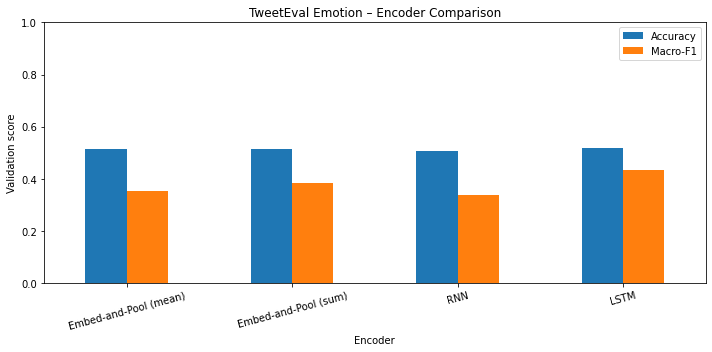

In [24]:
ax = (
    results_df
    .set_index("Encoder")[["Accuracy", "Macro-F1"]]
    .plot(kind="bar", figsize=(10, 5), rot=15)
)

ax.set_title("TweetEval Emotion – Encoder Comparison")
ax.set_ylabel("Validation score")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"

def run_experiment(
    name,
    encoder_type="mean",
    pretrained=True,
    freeze_embeddings=True,
    hidden_size=20,
    dropout=0.1,
    word_dropout=0.0,
    hidden_size1=50,
    hidden_size2=50,
    learning_rate=1e-3,
    weight_decay=1e-4,
    batch_size=64,
    train_fraction=1.0,
    epochs=10,
    seed=13
):
    torch.manual_seed(seed)

    if not pretrained and freeze_embeddings:
        raise ValueError("Random embeddings must be trainable.")

    # The GloVe vectors loaded earlier in the notebook
    embedding_matrix = torch.tensor(
        trained_embeddings.vectors,
        dtype=torch.float32
    )

    if not pretrained:
        nn.init.normal_(embedding_matrix, mean=0, std=0.1)
        embedding_matrix[pad_id].zero_()

    # Select encoder
    encoder_kwargs = {
        "embedding_matrix": embedding_matrix,
        "padding_idx": pad_id,
        "freeze_embeddings": freeze_embeddings
    }

    if encoder_type in ["mean", "sum"]:
        encoder = EmbedAndPoolEncoder(
            average_pool=(encoder_type == "mean"),
            **encoder_kwargs
        )

    elif encoder_type == "rnn":
        encoder = RNNEncoder(
            hidden_size=hidden_size,
            **encoder_kwargs
        )

    elif encoder_type == "lstm":
        encoder = LSTMEncoder(
            hidden_size=hidden_size,
            word_dropout=word_dropout,
            **encoder_kwargs
        )

    else:
        raise ValueError(f"Unknown encoder: {encoder_type}")

    # Same classification architecture
    model = SoftmaxRegressor(
        encoder=encoder,
        num_classes=len(labels),
        hidden_size1=hidden_size1,
        hidden_size2=hidden_size2,
        dropout=dropout
    ).to(device)

    # Reuse the encoded tweets from cell 17
    if train_fraction == 1.0:
        selected_train_data = train_data
    elif 0 < train_fraction < 1:
        indices, _ = train_test_split(
            np.arange(len(train_data)),
            train_size=train_fraction,
            stratify=dataset["train"]["label"],
            random_state=42
        )
        selected_train_data = Subset(train_data, indices)
    else:
        raise ValueError("train_fraction must be in (0, 1].")

    def collate(batch):
        return collate_labelled_texts(
            batch, padding_value=pad_id
        )

    experiment_train_loader = DataLoader(
        selected_train_data,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate
    )

    experiment_val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate
    )

    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    history = []
    best_result = None
    best_val_loss = float("inf")

    for epoch in range(1, epochs + 1):

        train_metrics = training_one_epoch(
            model, experiment_train_loader,
            optimizer, criterion, device
        )

        val_metrics = evaluate(
            model, experiment_val_loader,
            criterion, device
        )

        y_true = [
            y for batch in val_metrics["labels"] for y in batch
        ]
        y_pred = [
            y for batch in val_metrics["predictions"] for y in batch
        ]

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=list(range(len(labels))),
            average="macro",
            zero_division=0
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": macro_f1
        })

        # Select the best epoch using validation loss
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_result = {
                "experiment": name,
                "encoder": encoder_type,
                "embedding_dim": trained_embeddings.num_dims,
                "seed": seed,
                "best_epoch": epoch,
                "accuracy": val_metrics["accuracy"],
                "macro_f1": macro_f1
            }

    print(
        f"{name}: "
        f"Accuracy={best_result['accuracy']:.3f}, "
        f"Macro-F1={best_result['macro_f1']:.3f}"
    )

    return best_result, pd.DataFrame(history)

In [26]:
experiments = [
    {"name": "Mean Pool", "encoder_type": "mean"},
    {"name": "Sum Pool", "encoder_type": "sum"},
    {"name": "RNN", "encoder_type": "rnn"},
    {"name": "LSTM", "encoder_type": "lstm"}
]

results = []
histories = {}

for config in experiments:
    result, history = run_experiment(
        **config,
        epochs=10
    )

    results.append(result)
    histories[config["name"]] = history

results_df = pd.DataFrame(results)
display(results_df)

Mean Pool: Accuracy=0.527, Macro-F1=0.404
Sum Pool: Accuracy=0.503, Macro-F1=0.395
RNN: Accuracy=0.524, Macro-F1=0.381
LSTM: Accuracy=0.521, Macro-F1=0.433


,experiment,encoder,embedding_dim,seed,best_epoch,accuracy,macro_f1
0,Mean Pool,mean,25,13,6,0.526738,0.404036
1,Sum Pool,sum,25,13,6,0.502674,0.395056
2,RNN,rnn,25,13,10,0.524064,0.380565
3,LSTM,lstm,25,13,10,0.521390,0.433059


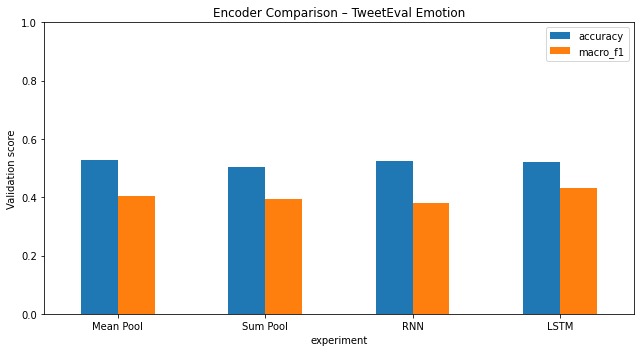

In [27]:
ax = (
    results_df
    .set_index("experiment")[["accuracy", "macro_f1"]]
    .plot(kind="bar", figsize=(9, 5), rot=0)
)

ax.set_title("Encoder Comparison – TweetEval Emotion")
ax.set_ylabel("Validation score")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

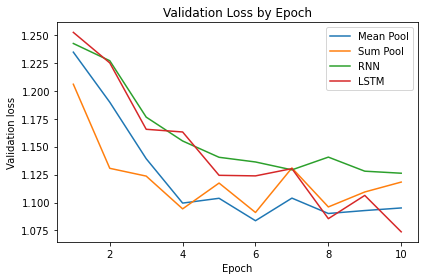

In [28]:
for name, history in histories.items():
    plt.plot(
        history["epoch"],
        history["val_loss"],
        label=name
    )

plt.title("Validation Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
lstm_results = []

for hidden_size in [20, 50, 100]:
    result, _ = run_experiment(
        name=f"LSTM hidden={hidden_size}",
        encoder_type="lstm",
        hidden_size=hidden_size,
        epochs=20
    )

    lstm_results.append(result)

display(pd.DataFrame(lstm_results))

LSTM hidden=20: Accuracy=0.521, Macro-F1=0.433
LSTM hidden=50: Accuracy=0.548, Macro-F1=0.470
LSTM hidden=100: Accuracy=0.553, Macro-F1=0.475


,experiment,encoder,embedding_dim,seed,best_epoch,accuracy,macro_f1
0,LSTM hidden=20,lstm,25,13,10,0.521390,0.433059
1,LSTM hidden=50,lstm,25,13,10,0.548128,0.470228
2,LSTM hidden=100,lstm,25,13,9,0.553476,0.474673


In [30]:
data_size_results = []

for fraction in [0.25, 0.5, 1.0]:
    result, _ = run_experiment(
        name=f"LSTM {int(fraction * 100)}% data",
        encoder_type="lstm",
        train_fraction=fraction,
        epochs=20
    )

    data_size_results.append(result)

display(pd.DataFrame(data_size_results))

LSTM 25% data: Accuracy=0.521, Macro-F1=0.391
LSTM 50% data: Accuracy=0.519, Macro-F1=0.424
LSTM 100% data: Accuracy=0.521, Macro-F1=0.433


,experiment,encoder,embedding_dim,seed,best_epoch,accuracy,macro_f1
0,LSTM 25% data,lstm,25,13,18,0.521390,0.390779
1,LSTM 50% data,lstm,25,13,13,0.518717,0.423799
2,LSTM 100% data,lstm,25,13,10,0.521390,0.433059


In [31]:
repeated_results = []

for seed in [0, 1, 2]:
    for encoder_type in ["mean", "lstm"]:
        result, _ = run_experiment(
            name=encoder_type,
            encoder_type=encoder_type,
            seed=seed,
            epochs=20
        )

        repeated_results.append(result)

repeated_df = pd.DataFrame(repeated_results)

repeated_df.to_csv(
    results_folder / "repeated_seed_results.csv",
    index=False,
)

display(
    repeated_df.groupby("encoder")["macro_f1"]
    .agg(["mean", "std"])
)

mean: Accuracy=0.535, Macro-F1=0.418
lstm: Accuracy=0.543, Macro-F1=0.454
mean: Accuracy=0.540, Macro-F1=0.432
lstm: Accuracy=0.537, Macro-F1=0.450
mean: Accuracy=0.532, Macro-F1=0.392
lstm: Accuracy=0.535, Macro-F1=0.424


,mean,std
encoder,,
lstm,0.442861,0.016069
mean,0.414141,0.020041
